# A/B тест новой формы оплаты ЖКХ
Гипотеза: форма с автозаполнением реквизитов увеличит долю успешных оплат ЖКХ.
Ключевая метрика: конверсия из шага 1 (открыл форму) в шаг 4 (успешная оплата).

План:
1. EDA и очистка данных
2. Дизайн теста (единица рандомизации, метрики и гипотезы, MDE и мощность)
3. Проверка рандомизации (SRM, баланс признаков)
4. Выбор критерия и его проверка на A/A
5. Результаты теста
6. Вывод и рекомендация

Блок «Дизайн теста» стоит после очистки данных, потому что базовая конверсия и разброс метрики берутся из очищенных данных контрольной группы: исторических данных до теста у нас нет. Разность между A и B при расчёте дизайна не используется.

In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
RNG = np.random.default_rng(42)
fp = lambda v: '—' if pd.isna(v) else ('<0.001' if v < 0.001 else round(float(v), 4))   # аккуратный вывод p-value
COL = {'A': '#8d99ae', 'B': '#FFD343'}   # единые цвета групп на всех графиках
ACC = '#2f9e6b'                          # зелёный акцент для оценок эффекта (не привязан к группе)

PATH = r'D:\Download\Данные_Т-Банк_осень2026.xlsx'   # путь к файлу с данными
users = pd.read_excel(PATH, sheet_name='Пользователи')
pay = pd.read_excel(PATH, sheet_name='Платежи')

# Шаг 1. EDA-анализ

## 1.1. Лист «Пользователи»

In [2]:
users.head()

,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


In [3]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1504 entries, 0 to 1503
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      1504 non-null   int64 
 1   group        1503 non-null   object
 2   age          1504 non-null   int64 
 3   city         1503 non-null   object
 4   device_type  1504 non-null   object
dtypes: int64(2), object(3)
memory usage: 58.9+ KB


In [4]:
users.describe(include='all')

,user_id,group,age,city,device_type
count,1504.000000,1503,1504.000000,1503,1504
unique,NaN,2,NaN,3,2
top,NaN,A,NaN,Москва,android
freq,NaN,752,NaN,595,777
mean,1769.787234,NaN,32.745346,NaN,NaN
std,571.592080,NaN,8.410915,NaN,NaN
min,1001.000000,NaN,-5.000000,NaN,NaN
25%,1376.750000,NaN,27.000000,NaN,NaN
50%,1752.500000,NaN,33.000000,NaN,NaN
75%,2128.250000,NaN,38.000000,NaN,NaN


In [5]:
print('Пропуски:')
print(users.isna().sum())
print('\nДубликаты user_id:', users['user_id'].duplicated().sum())
for c in ['group', 'city', 'device_type']:
    print(f'\n{c}:')
    print(users[c].value_counts(dropna=False))

Пропуски:
user_id        0
group          1
age            0
city           1
device_type    0
dtype: int64

Дубликаты user_id: 0

group:
group
A      752
B      751
NaN      1
Name: count, dtype: int64

city:
city
Москва    595
Регион    514
СПб       394
NaN         1
Name: count, dtype: int64

device_type:
device_type
android    777
ios        727
Name: count, dtype: int64


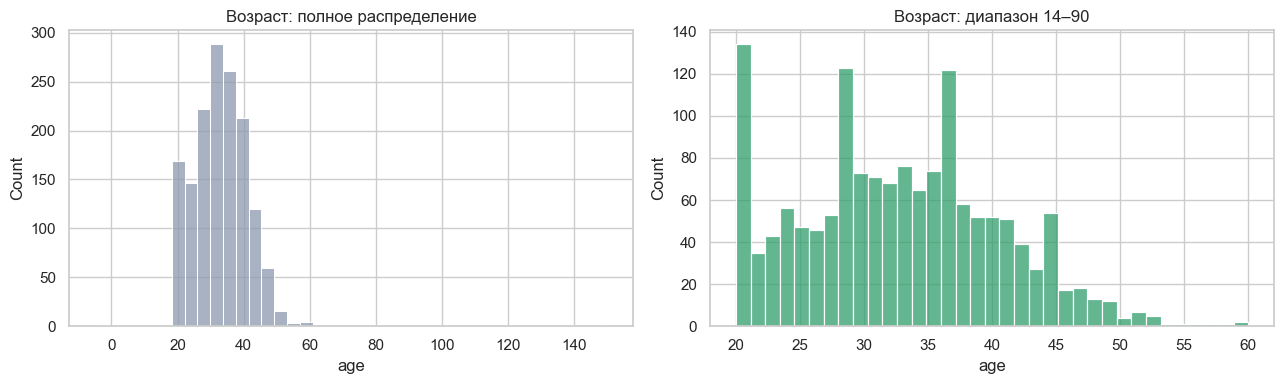

Записи с пропусками или невозможным возрастом:


,user_id,group,age,city,device_type
1500,9001,NaN,25,Москва,ios
1501,9002,A,-5,СПб,android
1502,9003,B,150,Регион,ios
1503,9004,A,30,NaN,android


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(users['age'], bins=40, ax=ax[0], color='#8d99ae')
ax[0].set_title('Возраст: полное распределение')
sns.histplot(users.loc[users['age'].between(14, 90), 'age'], bins=35, ax=ax[1], color=ACC)
ax[1].set_title('Возраст: диапазон 14–90')
plt.tight_layout(); plt.show()

print('Записи с пропусками или невозможным возрастом:')
bad_users = users[users[['group', 'city']].isna().any(axis=1) | ~users['age'].between(14, 100)]
bad_users

Выводы:

* 1504 пользователя, дублей user_id нет, группы почти поровну (A: 752, B: 751).
* Найдены 4 «подозрительные» записи с id 9001–9004 (остальные id идут подряд с 1001 по 2500): нет группы (9001), возраст −5 (9002), возраст 150 (9003), нет города (9004).
* Возраст усечён снизу на 20 годах (98 пользователей ровно в 20), то есть в данных, скорее всего, есть нижняя обрезка. Возраст в метриках не участвует, поэтому на выводы это не влияет.

## 1.2. Лист «Платежи»

In [7]:
pay.head()

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


In [8]:
pay.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2661 entries, 0 to 2660
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   payment_id       2661 non-null   int64         
 1   user_id          2660 non-null   float64       
 2   group            2661 non-null   object        
 3   step1_opened     2661 non-null   datetime64[ns]
 4   step2_entered    2256 non-null   datetime64[ns]
 5   step3_confirmed  1719 non-null   datetime64[ns]
 6   step4_success    1522 non-null   datetime64[ns]
dtypes: datetime64[ns](4), float64(1), int64(1), object(1)
memory usage: 145.7+ KB


In [9]:
steps = ['step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']

print('Пропуски (NaT на шагах воронки — это отвал, а не ошибка данных):')
print(pay.isna().sum())
print('\nДубликаты payment_id:', pay['payment_id'].duplicated().sum())
print('Период теста:', pay['step1_opened'].min(), '-', pay['step1_opened'].max())


Пропуски (NaT на шагах воронки — это отвал, а не ошибка данных):
payment_id            0
user_id               1
group                 0
step1_opened          0
step2_entered       405
step3_confirmed     942
step4_success      1139
dtype: int64

Дубликаты payment_id: 0
Период теста: 2024-04-01 00:19:00 - 2024-04-30 23:17:00


       step1→step2  step2→step3  step3→step4
count       2256.0       1719.0       1522.0
mean           2.4          4.5          5.5
std            1.9          1.9          1.1
min            1.0          1.0          1.0
50%            1.0          4.0          6.0
95%            6.0          8.0          7.0
99%            8.0          9.0          8.0
max           13.0         11.0          9.0


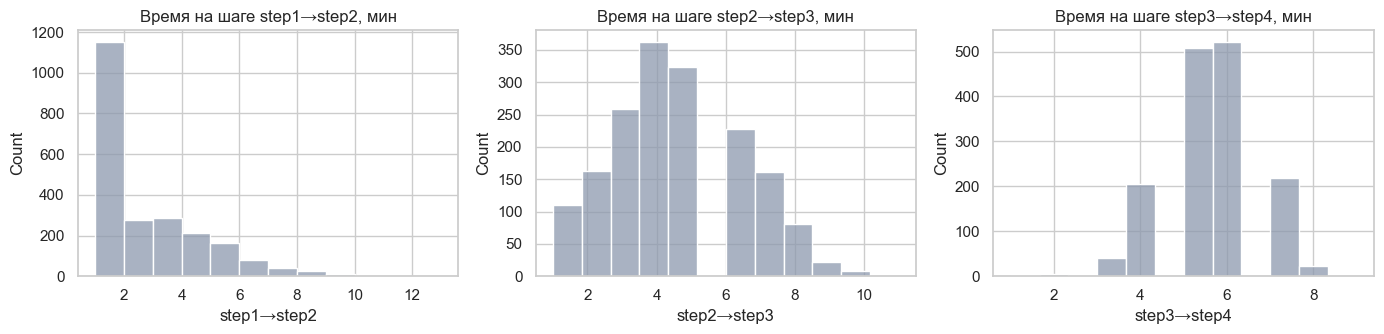

In [10]:
dur = pd.DataFrame({f'{a[:5]}→{b[:5]}': (pay[b] - pay[a]).dt.total_seconds() / 60 for a, b in zip(steps, steps[1:])})
print(dur.describe(percentiles=[.5, .95, .99]).round(1))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for i, c in enumerate(dur.columns):
    sns.histplot(dur[c].dropna(), bins=12, ax=ax[i], color='#8d99ae')
    ax[i].set_title(f'Время на шаге {c}, мин')
plt.tight_layout(); plt.show()

Выводы:

* 2661 попытка оплаты за период 1–30 апреля 2024, дублей payment_id нет. В условии указано ~8000 платежей, в файле 2661; анализируем то, что есть, а расхождение стоит уточнить у владельца данных.
* Пропуски в `step2–step4` — это не ошибки данных, а отвал воронки: ни разу шаг не наступал раньше предыдущего и не было успеха без предыдущего шага. Воронка логически целостна.
* Время на шагах правдоподобно (медианы 1, 4 и 6 минут, максимум 13). Исключение — два служебных платежа 99001 и 99002: последний шаг они прошли за 1 минуту, а у всех остальных платежей минимум 2 минуты. Время записано с точностью до минуты, поэтому различия быстрее минуты в данных не видны.
* Проблемные записи: платёж без `user_id` (99003); платёж 99002 с группой B у пользователя 1010, который в листе пользователей лежит в группе A (пользователь «виден» в обеих группах); платёж 99001 с нестандартным номером и такой же «быстрой» оплатой. Логика воронки у него не нарушена, поэтому оставляем и проверяем влияние в разделе 5.5.

## 1.3. Связность листов

In [11]:
m = pay.merge(users[['user_id', 'group']].rename(columns={'group': 'group_user'}), on='user_id', how='left')

print('Платежей без user_id:', pay['user_id'].isna().sum())
print('Платежей с user_id, которого нет в «Пользователи»:', (pay['user_id'].notna() & ~pay['user_id'].isin(users['user_id'])).sum())
print('Пользователей без платежей:', (~users['user_id'].isin(pay['user_id'])).sum())

mismatch = m[m['group_user'].notna() & (m['group'] != m['group_user'])]
print('Платежей, где группа не совпадает с группой пользователя:', len(mismatch))
mismatch[['payment_id', 'user_id', 'group', 'group_user']]

Платежей без user_id: 1
Платежей с user_id, которого нет в «Пользователи»: 0
Пользователей без платежей: 3
Платежей, где группа не совпадает с группой пользователя: 1


,payment_id,user_id,group,group_user
2659,99002,1010.0,B,A


In [12]:
# user_id, у которых платежи есть в обеих группах, и аномальные id
print(pay.groupby('user_id')['group'].nunique().loc[lambda s: s > 1])
print('\nПлатежи с «нестандартными» номерами (payment_id > 90000):')
pay[pay['payment_id'] > 90000]

user_id
1010.0    2
Name: group, dtype: int64

Платежи с «нестандартными» номерами (payment_id > 90000):


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
2658,99001,1005.0,A,2024-04-05 10:30:00,2024-04-05 10:33:00,2024-04-05 10:38:00,2024-04-05 10:39:00
2659,99002,1010.0,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00
2660,99003,NaN,A,2024-04-12 09:15:00,NaT,NaT,NaT


## 1.4. Очистка данных

In [13]:
n_users0, n_pay0 = len(users), len(pay)
clean_log = []

# --- пользователи ---
users_c = users.copy()
bad_age = ~users_c['age'].between(14, 100)
users_c.loc[bad_age, 'age'] = np.nan                               # невозможный возраст -> NaN, возраст в метриках не участвует
clean_log.append(('пользователи', 'невозможный возраст (-5, 150) -> NaN', int(bad_age.sum()), 'запись сохраняем'))
no_grp = users_c['group'].isna().sum()
users_c = users_c.dropna(subset=['group'])
clean_log.append(('пользователи', 'нет группы A/B', int(no_grp), 'удаляем: нельзя отнести к группе'))

clean_log.append(('пользователи', 'нет города (id 9004)', int(users_c['city'].isna().sum()), 'сохраняем: город нужен только для среза по городу'))

# --- платежи ---
no_uid = pay['user_id'].isna().sum()
pay_c = pay.dropna(subset=['user_id']).copy()
pay_c['user_id'] = pay_c['user_id'].astype(int)
clean_log.append(('платежи', 'нет user_id', int(no_uid), 'удаляем: нельзя посчитать на уровне пользователя'))

pay_c = pay_c.merge(users_c[['user_id', 'group']].rename(columns={'group': 'group_user'}), on='user_id', how='left')
conflict = (pay_c['group'] != pay_c['group_user']).sum()
pay_c = pay_c[pay_c['group'] == pay_c['group_user']].drop(columns='group_user')
clean_log.append(('платежи', 'группа платежа != группе пользователя', int(conflict), 'удаляем: источник истины — лист пользователей'))

# анализируемая популяция: пользователи, открывшие форму хотя бы раз
no_pay = (~users_c['user_id'].isin(pay_c['user_id'])).sum()
users_c = users_c[users_c['user_id'].isin(pay_c['user_id'])].copy()
clean_log.append(('пользователи', 'нет ни одной попытки оплаты', int(no_pay), 'вне популяции теста (ими оказались записи с аномальным возрастом)'))

pay_c['success'] = pay_c['step4_success'].notna().astype(int)
pay_c['s2'] = pay_c['step2_entered'].notna().astype(int)
pay_c['s3'] = pay_c['step3_confirmed'].notna().astype(int)

pd.DataFrame(clean_log, columns=['лист', 'проблема', 'записей', 'решение'])

,лист,проблема,записей,решение
0,пользователи,"невозможный возраст (-5, 150) -> NaN",2,запись сохраняем
1,пользователи,нет группы A/B,1,удаляем: нельзя отнести к группе
2,пользователи,нет города (id 9004),1,сохраняем: город нужен только для среза по городу
3,платежи,нет user_id,1,удаляем: нельзя посчитать на уровне пользователя
4,платежи,группа платежа != группе пользователя,1,удаляем: источник истины — лист пользователей
5,пользователи,нет ни одной попытки оплаты,2,вне популяции теста (ими оказались записи с ан...


In [14]:
print(f'Пользователей: {n_users0} -> {len(users_c)} | платежей: {n_pay0} -> {len(pay_c)}')
print(pay_c.groupby('group').agg(пользователей=('user_id', 'nunique'), попыток=('payment_id', 'size')))

Пользователей: 1504 -> 1501 | платежей: 2661 -> 2659
       пользователей  попыток
group                        
A                751     1308
B                750     1351


Решения по очистке:

* **Пользователь с разной группой на листах (1010).** В листе пользователей он в группе A, а платёж 99002 помечен B. Источник истины о назначении — лист пользователей, поэтому платёж 99002 удалён, а остальные платежи пользователя оставлены в A. Конфликт может означать смешение групп, поэтому в разделе 5.5 проверено, что результат не меняется, если убрать пользователя целиком.
* **Пользователи без попыток оплаты.** Метрика определена только для тех, кто открыл форму (шаг 1), и без попыток пользователь не может войти ни в числитель, ни в знаменатель. Таких оказалось двое (id 9002 и 9003, с невозможным возрастом), и ещё один без группы (9001). Они вне популяции теста, и их исключение ничего не меняет в оценке эффекта.
* **Пользователь без города (9004)** сохранён: город участвует только в срезе по городу, а в основной метрике не нужен.
* Платёж без `user_id` удаляем: тест рандомизирован по пользователям, без пользователя нельзя посчитать метрику на нужном уровне.
* Невозможный возраст заменяем на NaN: возраст в метриках не участвует.
* Платёж 99001 с нестандартным номером оставляем: он логически корректен. Устойчивость проверена в разделе 5.5.
* Выбросов по метрике нет: метрика бинарная, время на шагах в разумных пределах.
* Итог: было 1504 пользователя и 2661 платёж, осталось 1501 и 2659 (менее 0.2%).

## 1.5. Распределения и поведение по группам (описательно)

Смотрим на то, что помогает понять данные: число попыток, нагрузку по дням, время суток и день недели. Число попыток зависит от поведения пользователя после показа формы, поэтому формально группы по нему сравниваются в разделе 5.2 (H4a); здесь оно нужно, чтобы понять, что такое «несколько попыток». Воронку и результаты по группам разбираем позже, в шаге 5, после того как зафиксированы дизайн и критерии: так метрики не подбираются под увиденный эффект.

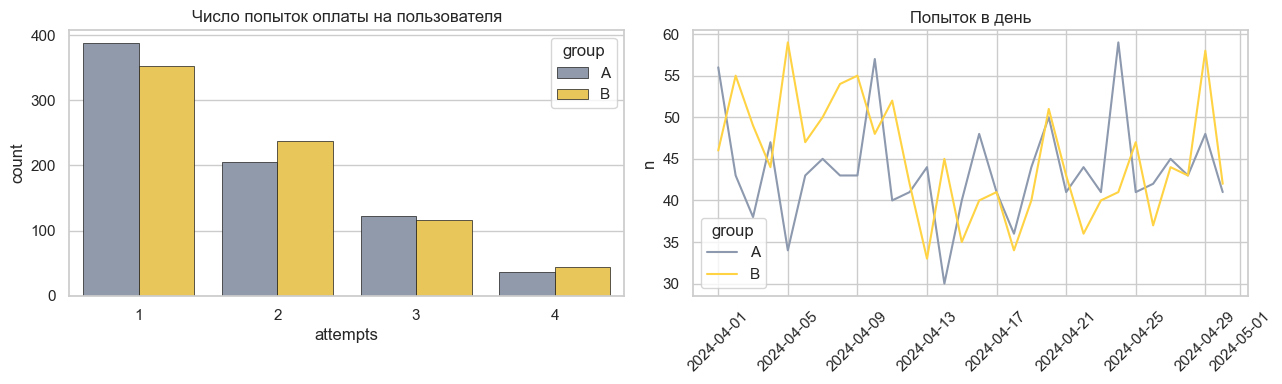

       mean   std
group            
A      1.74  0.90
B      1.80  0.91

Медианный интервал между попытками одного пользователя: 6.8 суток
Интервалов короче 24 часов: 3.2%
Доля попыток, которым уже предшествовала успешная оплата этого пользователя: 29%


In [15]:
att = pay_c.groupby(['group', 'user_id']).agg(attempts=('payment_id', 'size')).reset_index()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=att, x='attempts', hue='group', hue_order=['A', 'B'], palette=COL, edgecolor='k', linewidth=0.5, ax=ax[0])
ax[0].set_title('Число попыток оплаты на пользователя')
daily = pay_c.assign(day=pay_c['step1_opened'].dt.date).groupby(['day', 'group']).size().reset_index(name='n')
sns.lineplot(data=daily, x='day', y='n', hue='group', hue_order=['A', 'B'], palette=COL, ax=ax[1])
ax[1].set_title('Попыток в день'); ax[1].set_xlabel(''); ax[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

print(att.groupby('group')['attempts'].agg(['mean', 'std']).round(2))

# Что такое «несколько попыток» у одного пользователя: повтор после сбоя или следующий платёж? (обе группы вместе)
q = pay_c.sort_values(['user_id', 'step1_opened'])
gap_h = q.groupby('user_id')['step1_opened'].diff().dt.total_seconds() / 3600
prev_succ = q.groupby('user_id')['success'].cumsum() - q['success']
print(f'\nМедианный интервал между попытками одного пользователя: {gap_h.median() / 24:.1f} суток')
print(f'Интервалов короче 24 часов: {(gap_h <= 24).mean() * 100:.1f}%')
print(f'Доля попыток, которым уже предшествовала успешная оплата этого пользователя: {(prev_succ > 0).mean() * 100:.0f}%')

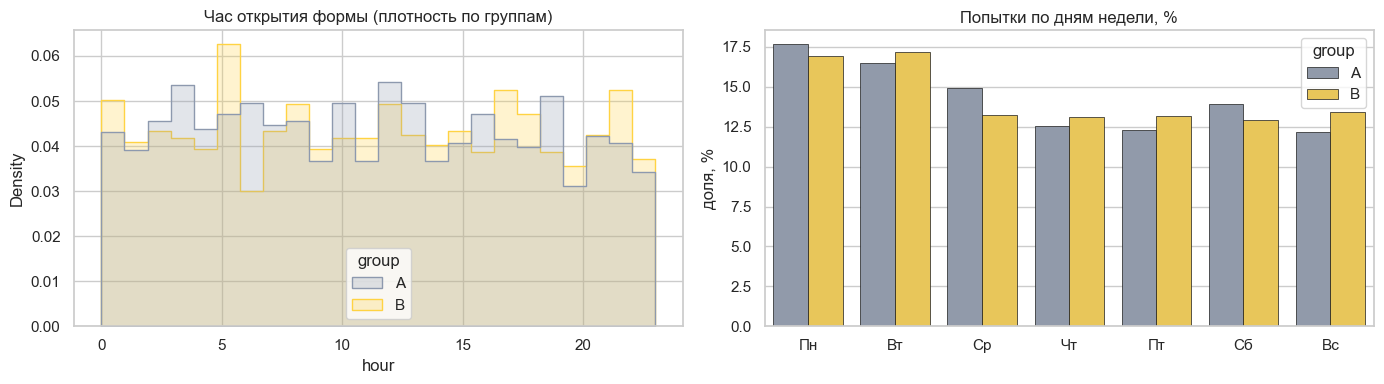

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=pay_c.assign(hour=pay_c['step1_opened'].dt.hour), x='hour', hue='group', hue_order=['A', 'B'], palette=COL, bins=24, stat='density', common_norm=False, element='step', ax=ax[0])
ax[0].set_title('Час открытия формы (плотность по группам)')
wd = pay_c.assign(wd=pay_c['step1_opened'].dt.dayofweek).groupby('group')['wd'].value_counts(normalize=True).mul(100).rename('доля, %').reset_index()
sns.barplot(data=wd, x='wd', y='доля, %', hue='group', hue_order=['A', 'B'], palette=COL, edgecolor='k', linewidth=0.5, ax=ax[1])
ax[1].set_xticklabels(['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']); ax[1].set_xlabel(''); ax[1].set_title('Попытки по дням недели, %')
plt.tight_layout(); plt.show()

Выводы по графикам:

* Число попыток на пользователя в группах похоже (1.74 и 1.80), поэтому сравнение «попытка к попытке» не искажено разной интенсивностью повторов. Нагрузка по дням в группах идёт параллельно, резких всплесков нет.
* Несколько попыток одного пользователя — это в основном не повторы после сбоя, а следующие платежи: медианный интервал между попытками около 7 суток, интервалов короче суток всего 3%, а почти 30% попыток сделано уже после успешной оплаты. Поэтому «попыток на пользователя» не является мерой трения формы, и для guardrail ниже (раздел 2.2) используется другая метрика.
* Попытки равномерно распределены по часам и дням недели в обеих группах, то есть группы наблюдались в одинаковых условиях и в одинаковое время.

# Шаг 2. Дизайн теста

Здесь фиксируем до анализа эффекта: кого сравниваем, что измеряем, какие гипотезы проверяем, по какому правилу принимаем решение и какой эффект тест в принципе способен обнаружить. Разность A и B в этом блоке не используется.

## 2.1. Параметры теста

| Параметр | Значение |
|---|---|
| Единица рандомизации | пользователь |
| Единица наблюдения | попытка оплаты (у одного пользователя от 1 до 4 попыток) |
| Популяция | пользователи, открывшие форму оплаты ЖКХ хотя бы раз (шаг 1) |
| Группы | A — действующая форма, B — форма с автозаполнением реквизитов |
| Период | 1–30 апреля 2024 |
| Размер после очистки | 751 пользователь в A и 750 в B (1308 и 1351 попытка) |
| Уровень значимости | α = 5%, двусторонний критерий |
| Мощность | 80% |

## 2.2. Метрики и гипотезы

**Основная метрика (по условию):** конверсия step1 → step4 = успешные оплаты / попытки оплаты. Это ratio-метрика: числитель и знаменатель суммируются по пользователям.

| № | Гипотеза | Метрика | Роль | Критерий |
|---|---|---|---|---|
| H1 | Новая форма меняет (по продукту — повышает) конверсию | конверсия step1 → step4 | **основная, по ней решение** | дельта-метод + кластерный бутстреп |
| H2 | Итог для пользователя тоже лучше | доля пользователей с ≥1 успешной оплатой | подтверждающая | бутстреп по пользователям (ДИ) |
| H3 | Улучшение идёт по всей воронке, а не на одном шаге | конверсия на шагах 1→2, 2→3, 3→4 | диагностика механизма | дельта-метод, поправка Холма |
| H4a | Форма не меняет число попыток на пользователя | попыток на пользователя | проверка знаменателя метрики H1 | Уэлч, двусторонний |
| H4b | Форма не создаёт трения: не растёт доля неудач, за которыми пользователь сразу пробует снова | доля неуспешных попыток с повторной попыткой в течение 24 часов | **guardrail** | дельта-метод |
| H5 | Форма не замедляет оплату | время на шагах | guardrail, описательно | Манн–Уитни |
| H6 | Эффект одинаков для разных устройств, городов и недель теста | эффект по сегментам и периодам | гетерогенность и устойчивость во времени, не влияет на решение | Cochran Q, поправка Холма |

**Правило решения** (по логике лекции 1.03, фреймворк Spotify): запускаем, если H1 подтверждена (значимое улучшение) и guardrail H4b не нарушен. H2, H3, H4a, H5, H6 помогают понять и проверить эффект, но решение не определяют.

**Почему guardrail устроен именно так.** Первая идея — «не растёт число попыток на пользователя». Но в данных (раздел 1.5) попытки разнесены на дни и часто идут после успешной оплаты: это следующие платежи, а не повторы после сбоя. Рост числа попыток мог бы означать не трение, а более частое использование формы. Поэтому H4a служит проверкой знаменателя основной метрики (чтобы она оставалась сопоставимой между группами), а трение измеряет H4b: пользователь не смог оплатить и сразу пробует снова.

**Почему тест двусторонний.** Продуктовая гипотеза говорит о росте, но решение «не запускать» принимается и при значимом ухудшении. Двусторонний тест при α = 5% эквивалентен проверке роста на уровне 2.5% и строже одностороннего теста на уровне 5%, зато не требует угадывать направление до теста, а доверительный интервал показывает ухудшение, если оно есть.

**Поправки на множественность.** Для H1 поправка не нужна: она единственная и определяет решение. Холма применяем только внутри диагностических семейств (3 шага воронки в H3 и 3 проверки неоднородности в H6: устройство, город, неделя), чтобы не получить ложную «неоднородность» или «шаг-виновник» из-за нескольких проверок. Guardrail H4b один, поэтому поправка ему не нужна.

## 2.3. MDE и размер выборки

MDE считаем по базовой конверсии и разбросу метрики **в контрольной группе A** и фактическим размерам групп. Разброс считаем на уровне пользователей по дельта-методу (подробнее о нём — в шаге 4): рандомизируем пользователей, а наблюдения — попытки.

In [17]:
def user_agg(df, num):
    """Сводим платежи к уровню пользователя: x — сумма числителя (успехи), n — число попыток."""
    return df.groupby(['group', 'user_id']).agg(x=(num, 'sum'), n=(num, 'size')).reset_index()

def ratio_var(x, n):
    """Отношение R = sum(x)/sum(n) и его дисперсия (дельта-метод, кластеры = пользователи)."""
    N, R = len(x), x.sum() / n.sum()
    nbar = n.mean()
    return R, (np.var(x, ddof=1) + R**2 * np.var(n, ddof=1) - 2 * R * np.cov(x, n, ddof=1)[0, 1]) / (N * nbar**2)

ua = user_agg(pay_c, 'success')
XA, NA = ua.loc[ua.group == 'A', 'x'].values, ua.loc[ua.group == 'A', 'n'].values
XB, NB = ua.loc[ua.group == 'B', 'x'].values, ua.loc[ua.group == 'B', 'n'].values

Z_A, Z_B = stats.norm.ppf(0.975), stats.norm.ppf(0.8)

# Разброс метрики берём только из контрольной группы A: так мы не подсматриваем эффект.
# Дисперсия отношения масштабируется как 1/число пользователей, поэтому для B берём ту же дисперсию на пользователя.
R_A, V_A = ratio_var(XA, NA)
se_design = np.sqrt(V_A * (1 + len(XA) / len(XB)))
mde_pp = (Z_A + Z_B) * se_design * 100
print(f'Базовая конверсия (A): {R_A*100:.1f}%')
print(f'SE разности по данным A: {se_design*100:.2f} п.п.')
print(f'MDE (α=5% двусторонний, мощность 80%): {mde_pp:.1f} п.п. = {mde_pp / (R_A*100) * 100:.0f}% от базовой конверсии')

# Сколько пользователей на группу нужно, чтобы поймать эффект заданной величины
var_user = V_A * len(XA)          # дисперсия метрики в пересчёте на одного пользователя
need = pd.DataFrame({'MDE, п.п.': [2, 3, 5, 8, 10]})
need['пользователей на группу'] = np.ceil(2 * (Z_A + Z_B)**2 * var_user / (need['MDE, п.п.'] / 100)**2).astype(int)
need['факт в тесте'] = len(XA)
need['нужно / факт'] = (need['пользователей на группу'] / need['факт в тесте']).round(1)
need

Базовая конверсия (A): 49.8%
SE разности по данным A: 1.93 п.п.
MDE (α=5% двусторонний, мощность 80%): 5.4 п.п. = 11% от базовой конверсии


,"MDE, п.п.",пользователей на группу,факт в тесте,нужно / факт
0,2,5458,751,7.3
1,3,2426,751,3.2
2,5,874,751,1.2
3,8,342,751,0.5
4,10,219,751,0.3


## 2.4. Мощность

Мощность считаем для правдоподобных эффектов, а не для наблюдённого: подстановка наблюдённого эффекта — это то же p-value в другой шкале (лекция 1.06).

In [18]:
def power(theta, se_):
    """Мощность двустороннего критерия для истинного эффекта theta при данной SE (нормальное приближение)."""
    lam = theta / se_
    return (1 - stats.norm.cdf(Z_A - lam)) + stats.norm.cdf(-Z_A - lam)

rows = [{'правдоподобный эффект, п.п.': th, 'мощность': power(th / 100, se_design)} for th in [2, 4, 6, 8, 10, 15]]
pd.DataFrame(rows).set_index('правдоподобный эффект, п.п.').round(3)

,мощность
"правдоподобный эффект, п.п.",
2,0.180
4,0.547
6,0.876
8,0.986
10,0.999
15,1.000


Выводы по дизайну:

* Базовая конверсия 49.8%, SE разности 1.93 п.п., **MDE около 5.4 п.п.** (~11% от базовой конверсии): эффект меньше этого тест находил бы реже, чем в 80% случаев.
* Для эффекта 5 п.п. на группу нужно около 870 пользователей, для 3 п.п. около 2400 (в 3.2 раза больше фактического), для 2 п.п. около 5500 (в 7.3 раза больше). Фактически в группах по 750 пользователей.
* Для эффектов от 6 п.п. мощность выше 87%. Для эффектов 2–4 п.п. мощность низкая (18–55%): тест мог бы их не заметить.
* Ограничение дизайна: ожидаемый эффект и минимально значимый для бизнеса эффект до теста не были зафиксированы. Если продукт считает ценным прирост в 2–4 п.п., такой тест для него слишком мал. Для следующих тестов нужно сначала согласовать этот порог, а потом считать выборку под него.
* На вывод по этому тесту ограничение не влияет: наблюдённый эффект (раздел 5.1) примерно втрое выше MDE, а нижняя граница интервала лежит выше MDE.

# Шаг 3. Проверка рандомизации

Единица рандомизации — пользователь. Проверяем:
1. SRM — соотношение размеров групп (χ², ожидаем 50/50, порог p < 0.001)
2. Баланс признаков до воздействия: устройство, город (χ²), возраст (Манн–Уитни: возраст не нормален и усечён снизу)
3. Баланс по времени: в какой период теста пользователь впервые открыл форму (χ²), чтобы назначение групп не менялось внутри теста

In [19]:
cnt = users_c['group'].value_counts().sort_index()
print(cnt.to_dict())
print('SRM (χ², 50/50): p =', round(stats.chisquare(cnt.values).pvalue, 4))

rows = []
for c in ['device_type', 'city']:
    ct = pd.crosstab(users_c['group'], users_c[c])
    rows.append({'признак': c, 'тест': 'χ²', 'p-value': stats.chi2_contingency(ct)[1]})
a_age = users_c.loc[users_c['group'] == 'A', 'age'].dropna(); b_age = users_c.loc[users_c['group'] == 'B', 'age'].dropna()
rows.append({'признак': 'age', 'тест': 'Манн–Уитни', 'p-value': stats.mannwhitneyu(a_age, b_age).pvalue})
first_t = pay_c.groupby('user_id')['step1_opened'].min()
users_c['first_period'] = ((users_c['user_id'].map(first_t).dt.day - 1) // 7).clip(upper=3)   # 1–7, 8–14, 15–21, 22–30 апреля
rows.append({'признак': 'период первой попытки', 'тест': 'χ²', 'p-value': stats.chi2_contingency(pd.crosstab(users_c['group'], users_c['first_period']))[1]})
bal = pd.DataFrame(rows); bal['p-value'] = bal['p-value'].round(4)
bal

{'A': 751, 'B': 750}
SRM (χ², 50/50): p = 0.9794


,признак,тест,p-value
0,device_type,χ²,0.0595
1,city,χ²,0.4404
2,age,Манн–Уитни,0.8216
3,период первой попытки,χ²,0.1730


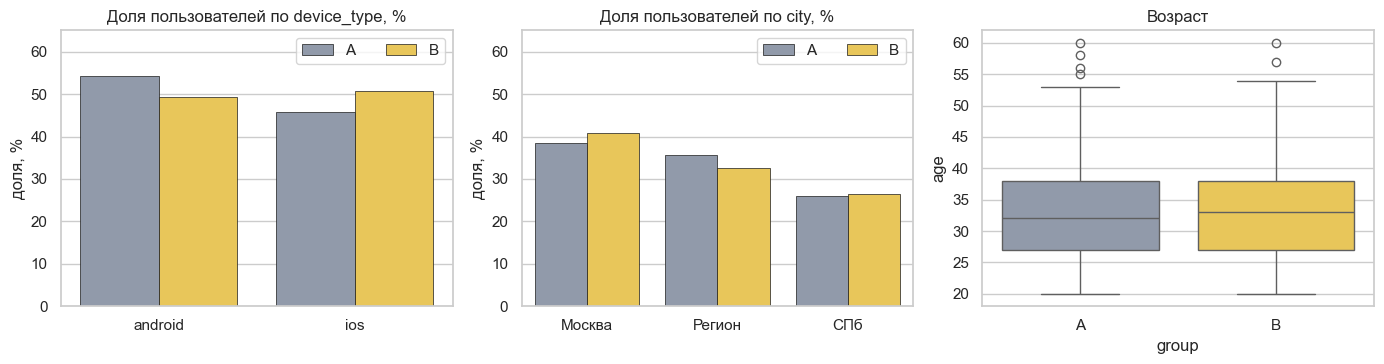

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for i, c in enumerate(['device_type', 'city']):
    share = users_c.groupby('group')[c].value_counts(normalize=True).mul(100).rename('доля, %').reset_index()
    sns.barplot(data=share, x=c, y='доля, %', hue='group', palette=COL, edgecolor='k', linewidth=0.5, ax=ax[i])
    ax[i].set_title(f'Доля пользователей по {c}, %'); ax[i].set_xlabel(''); ax[i].set_ylim(0, 65); ax[i].legend(loc='upper right', ncol=2)
sns.boxplot(data=users_c, x='group', y='age', hue='group', palette=COL, ax=ax[2], legend=False)
ax[2].set_title('Возраст')
plt.tight_layout(); plt.show()

Выводы:

* SRM нет: p = 0.98, группы 751 и 750 пользователей.
* Возраст, город и период первой попытки сбалансированы (p = 0.82, 0.44 и 0.17).
* Устройство на границе (p = 0.06): в B немного больше iOS. Это не нарушение, а типичный случайный дисбаланс при нескольких проверках. Тем не менее конверсия может зависеть от устройства, поэтому в шаге 5 проверим, что вывод не зависит от этого дисбаланса: сегментный анализ и логит с поправкой на признаки.

# Шаг 4. Выбор критерия и проверка на A/A

**Зачем дельта-метод.** Рандомизируем пользователей, а наблюдения — попытки. Метрика — отношение сумм (успехи / попытки), у которого нет готовой формулы SE для зависимых попыток. Дельта-метод считает дисперсию отношения через дисперсии и ковариацию числителя и знаменателя **на уровне пользователей**:

Var(R) ≈ [Var(x) + R²·Var(n) − 2R·Cov(x, n)] / (N · n̄²), где x — успехи пользователя, n — его попытки, N — число пользователей, R = Σx / Σn.

Разность групп оцениваем по нормальному приближению: z = (R_B − R_A) / √(Var_A + Var_B), p-value берётся из стандартного нормального распределения.

**Независимая проверка:** кластерный бутстреп — ресэмплируем пользователей целиком вместе с их попытками, считаем разность и берём перцентили (лекция 1.01).

**Как работает A/A на реальных данных.** Эффекта по построению нет, если случайно перемешать метки A/B между пользователями. Поэтому много раз (5000) перемешиваем группы, считаем p-value обоих критериев и смотрим долю p < 0.05. Для корректного критерия она должна быть около 5%. Так проверяем, что критерий не «находит» эффект там, где его нет, и что дельта-метод не хуже наивного z-теста.

In [21]:
def ratio_delta(xa, na, xb, nb):
    """Разность отношений R_B - R_A. Возвращает разность, SE, z, двусторонний p-value."""
    Ra, Va = ratio_var(xa, na); Rb, Vb = ratio_var(xb, nb)
    se = np.sqrt(Va + Vb); d = Rb - Ra
    z = d / se
    return d, se, z, 2 * (1 - stats.norm.cdf(abs(z)))

def naive_z(xa, na, xb, nb):
    """Двухвыборочный z-тест для долей, как если бы все платежи были независимы."""
    pa, pb = xa.sum() / na.sum(), xb.sum() / nb.sum()
    pp = (xa.sum() + xb.sum()) / (na.sum() + nb.sum())
    se = np.sqrt(pp * (1 - pp) * (1 / na.sum() + 1 / nb.sum()))
    z = (pb - pa) / se
    return pb - pa, se, z, 2 * (1 - stats.norm.cdf(abs(z)))

# user_agg, ratio_var и данные XA, NA, XB, NB определены в блоке «Дизайн теста» (раздел 2.3)
print('Пользователей A/B:', len(XA), len(XB), '| платежей A/B:', NA.sum(), NB.sum())

Пользователей A/B: 751 750 | платежей A/B: 1308 1351


In [22]:
# Внутрипользовательская корреляция: зависимы ли попытки одного пользователя? Проверяем в каждой группе отдельно,
# чтобы эффект формы не вошёл в разброс между пользователями.
multi = pay_c.groupby('user_id').filter(lambda d: len(d) >= 2)
rows = []
for g, d in multi.groupby('group'):
    w = d.groupby('user_id')['success'].agg(['mean', 'size'])
    p0 = pay_c.loc[pay_c['group'] == g, 'success'].mean()
    rows.append({'группа': g, 'пользователей с ≥2 попытками': len(w),
                 'дисперсия доли успеха (факт)': w['mean'].var(),
                 'ожидаемая при независимых попытках': (p0 * (1 - p0) / w['size']).mean()})
pd.DataFrame(rows).set_index('группа').round(4)

,пользователей с ≥2 попытками,дисперсия доли успеха (факт),ожидаемая при независимых попытках
группа,,,
A,363,0.1003,0.1048
B,397,0.0963,0.0971


In [23]:
# A/A на реальных данных. Эффекта по построению нет, поэтому доля p < 0.05 у корректного критерия должна быть около 5%.
# 1) перемешиваем метки A/B между ПОЛЬЗОВАТЕЛЯМИ; 2) делим пополам только контрольную группу A (в ней нет никакого воздействия).
B_AA = 20000
def aa_rates(x_all, n_all, k):
    N = len(x_all); rej = {'наивный z-тест': 0, 'дельта-метод': 0}
    for _ in range(B_AA):
        idx = RNG.permutation(N); ia, ib = idx[:k], idx[k:]
        if naive_z(x_all[ia], n_all[ia], x_all[ib], n_all[ib])[3] < 0.05: rej['наивный z-тест'] += 1
        if ratio_delta(x_all[ia], n_all[ia], x_all[ib], n_all[ib])[3] < 0.05: rej['дельта-метод'] += 1
    return {k_: v / B_AA for k_, v in rej.items()}

aa = pd.DataFrame({'перемешивание A+B': aa_rates(np.concatenate([XA, XB]), np.concatenate([NA, NB]), len(XA)),
                   'деление группы A пополам': aa_rates(XA, NA, len(XA) // 2)})
aa.index.name = 'доля ложных срабатываний'
aa.round(4)

,перемешивание A+B,деление группы A пополам
доля ложных срабатываний,,
наивный z-тест,0.0528,0.0470
дельта-метод,0.0518,0.0526


Выводы:

* Оба критерия держат ошибку I рода на уровне номинальных 5% в обоих вариантах A/A (4.7–5.3% при 20 000 повторов; 95%-ный разброс самой симуляции около ±0.3 п.п.).
* Попытки одного пользователя оказались практически независимыми: фактическая дисперсия доли успеха между пользователями с ≥2 попытками близка к ожидаемой при независимости (в группе A 0.100 против 0.105, в группе B 0.096 против 0.097). Поэтому кластеризация на значимость не влияет, и наивный z-тест здесь тоже корректен.
* Основной критерий оставляем дельта-метод: он корректен по построению для рандомизации по пользователям и не зависит от того, что данные оказались «чистыми».

# Шаг 5. Результаты теста

## 5.1. Основная метрика: конверсия step1 → step4

In [24]:
d, se, z, p = ratio_delta(XA, NA, XB, NB)
ra, rb = XA.sum() / NA.sum(), XB.sum() / NB.sum()
ci = (d - 1.96 * se, d + 1.96 * se)

# Кластерный бутстреп (ресэмплируем пользователей внутри групп) — независимая проверка дельта-метода
B_BS = 10000
bs = np.empty(B_BS)
for i in range(B_BS):
    ia = RNG.integers(0, len(XA), len(XA)); ib = RNG.integers(0, len(XB), len(XB))
    bs[i] = XB[ib].sum() / NB[ib].sum() - XA[ia].sum() / NA[ia].sum()
ci_bs = np.percentile(bs, [2.5, 97.5])

main = pd.DataFrame({
    'A': [ra], 'B': [rb], 'разность, п.п.': [d * 100], 'ДИ дельта-метод, п.п.': [f'[{ci[0]*100:.1f}; {ci[1]*100:.1f}]'],
    'ДИ бутстреп, п.п.': [f'[{ci_bs[0]*100:.1f}; {ci_bs[1]*100:.1f}]'], 'отн. прирост, %': [d / ra * 100],
    'p-value': [p]}, index=['конверсия step1→step4'])
main['p-value'] = main['p-value'].map(fp)
main.round(4)

,A,B,"разность, п.п.","ДИ дельта-метод, п.п.","ДИ бутстреп, п.п.","отн. прирост, %",p-value
конверсия step1→step4,0.4977,0.644,14.6261,[10.9; 18.3],[10.9; 18.4],29.387,<0.001


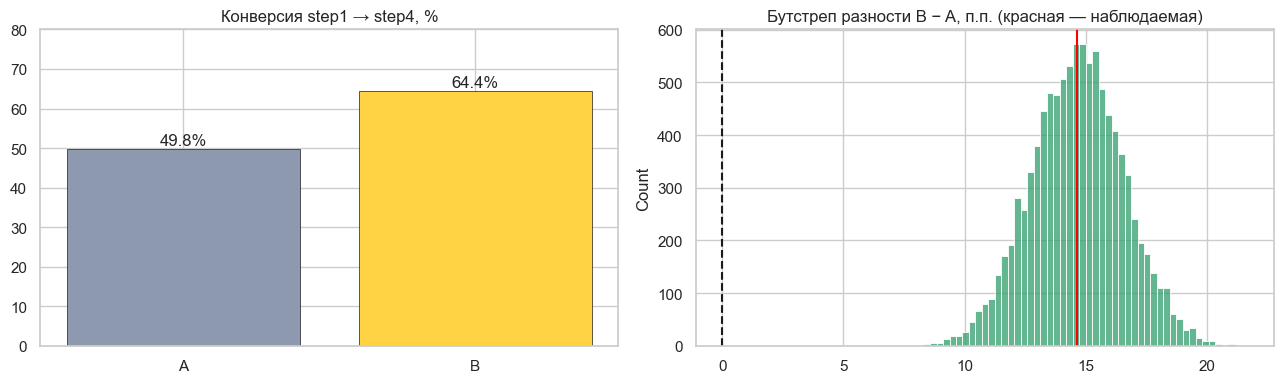

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(['A', 'B'], [ra * 100, rb * 100], color=[COL['A'], COL['B']], edgecolor='k', linewidth=0.5)
for i, v in enumerate([ra, rb]): ax[0].text(i, v * 100 + 1, f'{v*100:.1f}%', ha='center')
ax[0].set_ylim(0, 80); ax[0].set_title('Конверсия step1 → step4, %')
sns.histplot(bs * 100, bins=50, ax=ax[1], color=ACC)
ax[1].axvline(0, color='k', ls='--'); ax[1].axvline(d * 100, color='red')
ax[1].set_title('Бутстреп разности B − A, п.п. (красная — наблюдаемая)')
plt.tight_layout(); plt.show()

Выводы:

* Конверсия step1 → step4: **49.8% в A и 64.4% в B**, разность **+14.6 п.п.** (95% ДИ [10.9; 18.3]), относительный прирост около +29%. В пересчёте на объём: на каждые 1000 попыток оплаты приходится примерно на 146 успешных оплат больше.
* Дельта-метод и кластерный бутстреп дают практически одинаковый интервал, p < 0.001. Нижняя граница эффекта (+10.9 п.п.) вдвое выше MDE теста (5.4 п.п.).

## 5.2. Вторичные метрики и guardrail

In [26]:
pu = pay_c.groupby(['group', 'user_id']).agg(attempts=('success', 'size'), succ=('success', 'sum')).reset_index()
pu['any_success'] = (pu['succ'] > 0).astype(int)
A_, B_ = pu[pu.group == 'A'], pu[pu.group == 'B']

# H2: доля пользователей хотя бы с одной успешной оплатой. Доверительный интервал — бутстреп по пользователям (как в 5.1)
d1 = B_['any_success'].mean() - A_['any_success'].mean()
a_s, b_s = A_['any_success'].values, B_['any_success'].values
bs1 = np.array([b_s[RNG.integers(0, len(b_s), len(b_s))].mean() - a_s[RNG.integers(0, len(a_s), len(a_s))].mean() for _ in range(B_BS)])
ci1 = np.percentile(bs1, [2.5, 97.5])

# H4a: попыток на пользователя (проверка знаменателя метрики), Уэлч, двусторонний
t3 = stats.ttest_ind(B_['attempts'], A_['attempts'], equal_var=False)
d3 = B_['attempts'].mean() - A_['attempts'].mean(); se3 = d3 / t3.statistic

# H4b (guardrail): доля неуспешных попыток, за которыми тот же пользователь в течение 24 часов открыл форму снова.
# Метрика отношения (повторы / неудачи) на уровне пользователей — тот же дельта-метод.
q = pay_c.sort_values(['user_id', 'step1_opened']).copy()
q['gap_h'] = (q.groupby('user_id')['step1_opened'].shift(-1) - q['step1_opened']).dt.total_seconds() / 3600
fail = q[q['success'] == 0].copy(); fail['retry24'] = (fail['gap_h'] <= 24).astype(int)
uf = user_agg(fail, 'retry24')
xa4, na4 = uf.loc[uf.group == 'A', 'x'].values, uf.loc[uf.group == 'A', 'n'].values
xb4, nb4 = uf.loc[uf.group == 'B', 'x'].values, uf.loc[uf.group == 'B', 'n'].values
d4, se4, _, p4 = ratio_delta(xa4, na4, xb4, nb4)
print(f'H4b: неуспешных попыток A/B = {na4.sum()}/{nb4.sum()}, из них быстрых повторов = {xa4.sum()}/{xb4.sum()}')

sec = pd.DataFrame({
    'A': [A_['any_success'].mean(), A_['attempts'].mean(), xa4.sum() / na4.sum()],
    'B': [B_['any_success'].mean(), B_['attempts'].mean(), xb4.sum() / nb4.sum()],
    'разность': [d1, d3, d4],
    'ДИ 95%': [f'[{ci1[0]:.3f}; {ci1[1]:.3f}]', f'[{d3-1.96*se3:.2f}; {d3+1.96*se3:.2f}]', f'[{d4-1.96*se4:.3f}; {d4+1.96*se4:.3f}]'],
    'p-value': [np.nan, t3.pvalue, p4],
    'критерий': ['бутстреп по пользователям', 'Уэлч', 'дельта-метод'],
}, index=['H2: доля пользователей с ≥1 успешной оплатой', 'H4a: попыток на пользователя', 'H4b (guardrail): быстрый повтор после неудачи'])
sec['p-value'] = sec['p-value'].map(fp)
sec.round(4)

H4b: неуспешных попыток A/B = 657/481, из них быстрых повторов = 25/15


,A,B,разность,ДИ 95%,p-value,критерий
H2: доля пользователей с ≥1 успешной оплатой,0.6565,0.8040,0.1475,[0.104; 0.192],—,бутстреп по пользователям
H4a: попыток на пользователя,1.7417,1.8013,0.0597,[-0.03; 0.15],0.2003,Уэлч
H4b (guardrail): быстрый повтор после неудачи,0.0381,0.0312,-0.0069,[-0.028; 0.014],0.5181,дельта-метод


Выводы:

* Эффект виден и на уровне пользователей: доля пользователей хотя бы с одной успешной оплатой выросла с 65.7% до 80.4% (+14.8 п.п., бутстреп-ДИ [10.4; 19.2]). Значит, итог для человека улучшился, а не просто «добивать» оплату стали за несколько попыток.
* H4a: число попыток на пользователя почти не отличается (1.74 и 1.80, p = 0.20), поэтому знаменатель основной метрики в группах сопоставим.
* H4b (guardrail): быстрых повторов после неудачи в B не больше, чем в A (около 3–4% в обеих группах). Событий мало (несколько десятков), поэтому проверка грубая, но признаков трения нет. Гораздо важнее то, что неудач в B стало меньше: 481 против 657 при сопоставимом числе попыток.

## 5.3. Где именно растёт конверсия: шаги воронки

Абсолютные значения:
       step1  step2  step3  step4
group                            
A       1308   1061    758    651
B       1351   1194    960    870

Доля от шага 1, %:
       step1  step2  step3  step4
group                            
A      100.0   81.1   58.0   49.8
B      100.0   88.4   71.1   64.4


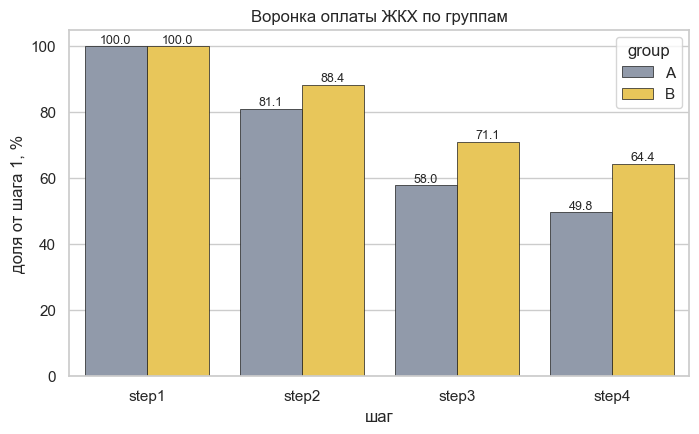

In [27]:
fun = pay_c.groupby('group').agg(step1=('payment_id', 'size'), step2=('s2', 'sum'), step3=('s3', 'sum'), step4=('success', 'sum'))
fun_pct = fun.div(fun['step1'], axis=0) * 100
print('Абсолютные значения:'); print(fun)
print('\nДоля от шага 1, %:'); print(fun_pct.round(1))

plot = fun_pct.reset_index().melt(id_vars='group', var_name='шаг', value_name='доля от шага 1, %')
plt.figure(figsize=(8, 4.5))
ax = sns.barplot(data=plot, x='шаг', y='доля от шага 1, %', hue='group', hue_order=['A', 'B'], palette=COL, edgecolor='k', linewidth=0.5)
for c in ax.containers: ax.bar_label(c, fmt='%.1f', fontsize=9)
plt.title('Воронка оплаты ЖКХ по группам'); plt.show()

In [28]:
rows = []
for name, col in [('step1 → step2', 's2'), ('step2 → step3', 's3'), ('step3 → step4', 'success')]:
    df = pay_c.copy()
    if name == 'step2 → step3': df = df[df['s2'] == 1]
    if name == 'step3 → step4': df = df[df['s3'] == 1]
    u_ = user_agg(df, col)
    xa, na = u_.loc[u_.group == 'A', 'x'].values, u_.loc[u_.group == 'A', 'n'].values
    xb, nb = u_.loc[u_.group == 'B', 'x'].values, u_.loc[u_.group == 'B', 'n'].values
    d_, se_, z_, p_ = ratio_delta(xa, na, xb, nb)
    rows.append({'шаг': name, 'A': xa.sum() / na.sum(), 'B': xb.sum() / nb.sum(), 'разность, п.п.': d_ * 100,
                 'ДИ, п.п.': f'[{(d_-1.96*se_)*100:.1f}; {(d_+1.96*se_)*100:.1f}]', 'p': p_})
fs = pd.DataFrame(rows).set_index('шаг')
fs['p (Холм)'] = multipletests(fs['p'], method='holm')[1]
fs['p'] = fs['p'].map(fp); fs['p (Холм)'] = fs['p (Холм)'].map(fp)
fs.round(4)

,A,B,"разность, п.п.","ДИ, п.п.",p,p (Холм)
шаг,,,,,,
step1 → step2,0.8112,0.8838,7.2628,[4.5; 10.1],<0.001,<0.001
step2 → step3,0.7144,0.8040,8.9600,[5.5; 12.4],<0.001,<0.001
step3 → step4,0.8588,0.9062,4.7411,[1.6; 7.8],0.0027,0.0027


In [29]:
# Если форма «упрощает заполнение», может измениться не только доля дошедших, но и время на шаге
dd = []
for a_, b_ in zip(steps, steps[1:]):
    d_ = (pay_c[b_] - pay_c[a_]).dt.total_seconds() / 60
    xa_, xb_ = d_[pay_c['group'] == 'A'].dropna(), d_[pay_c['group'] == 'B'].dropna()
    dd.append({'шаг': f'{a_} → {b_}', 'медиана A, мин': xa_.median(), 'медиана B, мин': xb_.median(), 'p (Манн–Уитни)': stats.mannwhitneyu(xa_, xb_).pvalue})
pd.DataFrame(dd).set_index('шаг').round(3)

,"медиана A, мин","медиана B, мин",p (Манн–Уитни)
шаг,,,
step1_opened → step2_entered,1.0,1.0,0.622
step2_entered → step3_confirmed,4.0,4.0,0.193
step3_confirmed → step4_success,6.0,6.0,0.784


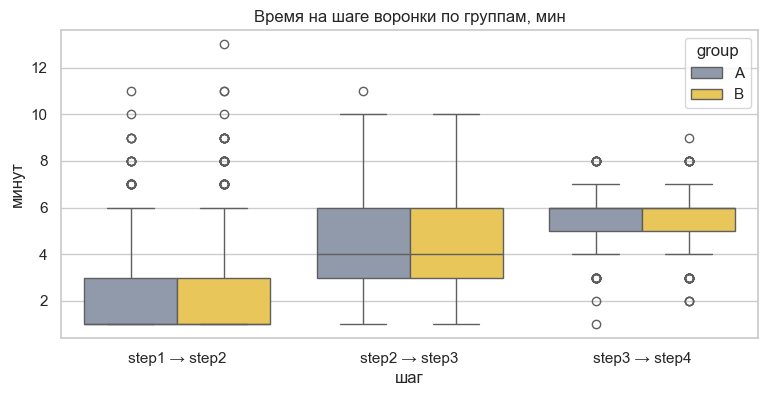

In [30]:
dl = []
for a_, b_ in zip(steps, steps[1:]):
    dl.append(pd.DataFrame({'group': pay_c['group'], 'шаг': f'{a_[:5]} → {b_[:5]}', 'минут': (pay_c[b_] - pay_c[a_]).dt.total_seconds() / 60}).dropna())
dl = pd.concat(dl)
plt.figure(figsize=(9, 4))
sns.boxplot(data=dl, x='шаг', y='минут', hue='group', hue_order=['A', 'B'], palette=COL)
plt.title('Время на шаге воронки по группам, мин'); plt.show()

Выводы:

* В группе B доля прошедших выше на каждом шаге воронки (от шага 1): step2 88% против 81%, step3 71% против 58%, step4 64% против 50%.
* Условные конверсии шагов тоже выше: step1 → step2 +7.3 п.п., step2 → step3 +9.0 п.п., step3 → step4 +4.7 п.п. (все значимы и после поправки Холма). Эффект идёт сразу с первых шагов, что согласуется с гипотезой про упрощённое заполнение реквизитов.
* Время на шагах в группах не отличается (медианы 1, 4 и 6 минут, боксплоты совпадают): форма влияет на то, дошёл ли пользователь до следующего шага, а не на скорость. Время записано с точностью до минуты, поэтому более мелкие различия не видны. Время считается только у дошедших до шага, а в B доходит больше людей, так что это описательная проверка, а не строгий тест.

## 5.4. Сегменты и устойчивость во времени: устройство, город, неделя теста

Сегменты заранее ограничены признаками, которые есть в данных. Смотрим не «значим / не значим» в каждом сегменте, а **различается ли эффект между сегментами** (тест на гетерогенность), и вводим поправку Холма на 3 теста. Срез по неделям теста нужен, чтобы заметить эффект новизны (эффект быстро затухает) или сезонность.

,срез,сегмент,польз. A/B,A,B,"эффект, п.п.","SE, п.п.","ДИ, п.п."
0,device_type,android,407/369,0.489,0.638,14.934,2.594,[9.9; 20.0]
1,device_type,ios,344/381,0.508,0.650,14.122,2.769,[8.7; 19.5]
2,city,Москва,288/306,0.468,0.651,18.267,2.965,[12.5; 24.1]
3,city,Регион,268/245,0.508,0.614,10.689,3.351,[4.1; 17.3]
4,city,СПб,194/199,0.526,0.669,14.238,3.613,[7.2; 21.3]
5,period,01–07 апр.,266/304,0.510,0.663,15.305,3.783,[7.9; 22.7]
6,period,08–14 апр.,258/279,0.523,0.660,13.608,3.914,[5.9; 21.3]
7,period,15–21 апр.,259/250,0.480,0.623,14.324,4.097,[6.3; 22.4]
8,period,22–30 апр.,342/327,0.483,0.629,14.619,3.560,[7.6; 21.6]


,срез,Q,ст. свободы,p-value,p (Холм)
0,device_type,0.0459,1,0.8304,1.0000
1,city,2.8954,2,0.2351,0.7053
2,period,0.1002,3,0.9918,1.0000


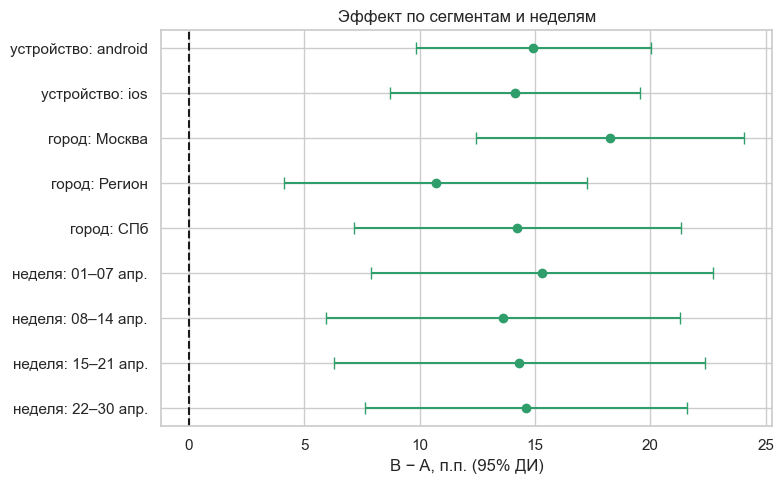

In [31]:
seg_users = users_c[['user_id', 'device_type', 'city']]
pay_s = pay_c.merge(seg_users, on='user_id')
pay_s['period'] = pd.cut(pay_s['step1_opened'].dt.day, [0, 7, 14, 21, 31], labels=['01–07 апр.', '08–14 апр.', '15–21 апр.', '22–30 апр.']).astype(str)

def seg_effect(df):
    u_ = user_agg(df, 'success')
    xa, na = u_.loc[u_.group == 'A', 'x'].values, u_.loc[u_.group == 'A', 'n'].values
    xb, nb = u_.loc[u_.group == 'B', 'x'].values, u_.loc[u_.group == 'B', 'n'].values
    d_, se_, _, p_ = ratio_delta(xa, na, xb, nb)
    return d_, se_, p_, len(xa), len(xb), xa.sum() / na.sum(), xb.sum() / nb.sum()

res, het = [], []
for dim in ['device_type', 'city', 'period']:
    ds, ses = [], []
    for lvl, df in pay_s.dropna(subset=[dim]).groupby(dim):
        d_, se_, p_, na_, nb_, ra_, rb_ = seg_effect(df)
        res.append({'срез': dim, 'сегмент': lvl, 'польз. A/B': f'{na_}/{nb_}', 'A': ra_, 'B': rb_, 'эффект, п.п.': d_ * 100, 'SE, п.п.': se_ * 100,
                    'ДИ, п.п.': f'[{(d_-1.96*se_)*100:.1f}; {(d_+1.96*se_)*100:.1f}]'})
        ds.append(d_); ses.append(se_)
    ds, ses = np.array(ds), np.array(ses); w = 1 / ses**2
    Q = (w * (ds - (w * ds).sum() / w.sum())**2).sum()                    # Cochran Q: эффекты одинаковы во всех сегментах
    het.append({'срез': dim, 'Q': Q, 'ст. свободы': len(ds) - 1, 'p-value': 1 - stats.chi2.cdf(Q, len(ds) - 1)})
seg = pd.DataFrame(res); het = pd.DataFrame(het)
het['p (Холм)'] = multipletests(het['p-value'], method='holm')[1]
display(seg.round(3)); display(het.round(4))

plt.figure(figsize=(8, 5))
lab = seg['срез'].replace({'device_type': 'устройство', 'city': 'город', 'period': 'неделя'}) + ': ' + seg['сегмент']
plt.errorbar(seg['эффект, п.п.'], range(len(seg)), xerr=1.96 * seg['SE, п.п.'], fmt='o', color=ACC, capsize=4)
plt.yticks(range(len(seg)), lab); plt.axvline(0, color='k', ls='--'); plt.xlabel('B − A, п.п. (95% ДИ)')
plt.gca().invert_yaxis(); plt.title('Эффект по сегментам и неделям'); plt.tight_layout(); plt.show()

Выводы:

* Эффект положителен во всех сегментах: Android +14.9 п.п., iOS +14.1 п.п.; Москва +18.3, СПб +14.2, Регион +10.7 п.п. Все интервалы лежат правее нуля.
* Различия эффекта между сегментами статистически не подтверждаются: по устройству p = 0.83, по городу p = 0.24, по неделе теста p = 0.99 (до поправки; после поправки Холма p ≥ 0.7). Разницу между Москвой и регионами (18.3 и 10.7) нельзя отличить от шума, поэтому запускать «только в Москве» оснований нет.
* Эффект не затухает со временем: по неделям он держится на уровне +13.6…+15.3 п.п. без тренда вниз, различия между неделями статистически не видны. Признаков эффекта новизны за 30 дней нет, хотя за более длительный срок это стоит проверить.
* Небольшой дисбаланс по устройству на результат не влияет: эффект на iOS и Android почти одинаков.

## 5.5. Устойчивость вывода

In [32]:
def eff(df):
    u_ = user_agg(df, 'success')
    xa, na = u_.loc[u_.group == 'A', 'x'].values, u_.loc[u_.group == 'A', 'n'].values
    xb, nb = u_.loc[u_.group == 'B', 'x'].values, u_.loc[u_.group == 'B', 'n'].values
    d_, se_, _, p_ = ratio_delta(xa, na, xb, nb)
    return d_ * 100, f'[{(d_-1.96*se_)*100:.1f}; {(d_+1.96*se_)*100:.1f}]', p_

rob = [('основной анализ (очищенные данные)',) + eff(pay_c)]

# a) вернуть записи, которые удалили как некорректные, в том виде, как они в данных (по группе платежа)
raw = pay.dropna(subset=['user_id']).copy(); raw['user_id'] = raw['user_id'].astype(int)
raw['success'] = raw['step4_success'].notna().astype(int)
rob.append(('без очистки (кроме платежа без user_id)',) + eff(raw))

# b) убрать «нестандартные» номера платежей (99xxx), которых нет в основной нумерации
rob.append(('без платежей с payment_id > 90000',) + eff(pay_c[pay_c['payment_id'] < 90000]))

# c) оставить только первую попытку каждого пользователя (полностью независимые наблюдения)
first = pay_c.sort_values('step1_opened').groupby('user_id').head(1)
rob.append(('только первая попытка пользователя',) + eff(first))

# d) убрать пользователя 1010 целиком (у него конфликт групп между листами — возможное смешение групп)
rob.append(('без пользователя 1010 (конфликт групп)',) + eff(pay_c[pay_c['user_id'] != 1010]))

# e) логистическая регрессия с поправкой на устройство, город, возраст; SE кластеризованы по пользователям
dfm = pay_s.dropna(subset=['city']).merge(users_c[['user_id', 'age']], on='user_id'); dfm['is_B'] = (dfm['group'] == 'B').astype(int)
dfm['age'] = dfm['age'].fillna(dfm['age'].median())
mm = smf.logit('success ~ is_B + C(device_type) + C(city) + age', data=dfm).fit(disp=0, cov_type='cluster', cov_kwds={'groups': dfm['user_id']})
ame = mm.get_margeff(at='overall').summary_frame().loc['is_B']
rob.append(('логит с device, city, age (средний предельный эффект)', ame['dy/dx'] * 100, f"[{ame['Conf. Int. Low']*100:.1f}; {ame['Cont. Int. Hi.']*100:.1f}]", ame['Pr(>|z|)']))

rt = pd.DataFrame(rob, columns=['вариант', 'эффект, п.п.', 'ДИ 95%', 'p-value']).set_index('вариант')
rt['p-value'] = rt['p-value'].map(fp)
rt.round(3)

,"эффект, п.п.",ДИ 95%,p-value
вариант,,,
основной анализ (очищенные данные),14.626,[10.9; 18.3],<0.001
без очистки (кроме платежа без user_id),14.652,[10.9; 18.4],<0.001
без платежей с payment_id > 90000,14.665,[11.0; 18.4],<0.001
только первая попытка пользователя,15.001,[10.1; 19.9],<0.001
без пользователя 1010 (конфликт групп),14.588,[10.9; 18.3],<0.001
"логит с device, city, age (средний предельный эффект)",14.381,[10.8; 17.9],<0.001


Выводы: оценка эффекта стабильна, **14.4–15.0 п.п.** во всех вариантах, интервалы похожи. Результат не зависит от очистки, от платежа с нестандартным номером, от пользователя с конфликтом групп, от повторных попыток и от поправки на устройство, город и возраст. Вариант «только первая попытка» особенно важен: число попыток — следствие поведения после воздействия, а первая попытка от него не зависит, и оценка по ней (+15.0 п.п.) совпадает с основной.

# Шаг 6. Вывод и рекомендация

## Рекомендация: **запускать новую форму на всех пользователей**

**Основания:**

* Конверсия step1 → step4 выросла с 49.8% до 64.4%: **+14.6 п.п.** (95% ДИ [10.9; 18.3]), около +29% относительно. На уровне пользователей доля с ≥1 успешной оплатой выросла с 65.7% до 80.4%.
* Эффект есть на каждом шаге воронки, во всех сегментах (устройство, город) и во все недели теста; значимых различий между сегментами нет.
* Тест корректен: SRM нет, группы сбалансированы, критерий проверен на A/A (ошибка I рода около 5%), результат устойчив к очистке данных и поправке на признаки. Размер эффекта намного больше MDE (5.4 п.п.).
* Guardrail выдержан: доля быстрых повторов после неудачи в B не выше, чем в A, а неудач в B стало заметно меньше.

**Ограничения и что сделать при запуске:**

* В тесте около 750 пользователей на группу и 30 дней: для такого эффекта достаточно, но эффекты меньше 5 п.п. и редкие события тест не покрывает.
* В данных нет метрик качества платежа (ошибки в реквизитах, возвраты, обращения в поддержку). Автозаполнение может увеличить долю ошибочных платежей, поэтому перед полным запуском это нужно подтвердить по логам.
* Прирост +29% относительно необычно велик для изменения формы. Это не повод сомневаться в корректности теста (все проверки пройдены), но повод проверить логи и запускать поэтапно.
* Автозаполнение не сократило время на шаге ввода реквизитов, хотя этого можно было ожидать. Время записано с точностью до минуты, поэтому это стоит перепроверить по более точным логам.
* Рекомендуется выкатывать поэтапно и оставить долгосрочный holdout (несколько процентов пользователей на старой форме), чтобы подтвердить, что эффект сохраняется после 30 дней.
* Расхождение объёма данных с описанием (2661 платёж в файле против ~8000 в условии) стоит уточнить у владельцев данных.
* Для следующих тестов: заранее согласовать минимально значимый для бизнеса эффект и считать выборку под него (раздел 2.4).